# 01 — Exploratory Data Analysis and Baseline Model
**Dataset:** Bank Account Fraud (BAF) Suite, Base variant (Jesus et al., 2022)

This notebook runs unchanged on the MacBook, the university PC and Google Colab.

**Where to put the data**
- **Mac / university PC:** put `Base.csv` in a folder called `data` inside the repository (e.g. `fraude_disseratation/data/Base.csv`). The notebook searches the current folder and its parent folders for it. The `data/` folder is excluded from Git by `.gitignore`, so copy it to each machine once.
- **Google Colab:** upload `Base.csv` to Google Drive and edit `COLAB_DATA_DIR` in the first code cell.
- **Anywhere else:** set the environment variable `DISSERTATION_DATA_DIR` to the folder containing `Base.csv`.

On the first run the CSV is converted to `Base.parquet`, which loads much faster afterwards.

In [40]:
import os
import sys
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

# ---- Work out where the data is, depending on which machine this is running on ----
COLAB_DATA_DIR = '/content/drive/MyDrive/Dissertation/data'  

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path(COLAB_DATA_DIR)
    MACHINE = 'Google Colab'
elif os.environ.get('DISSERTATION_DATA_DIR'):
    DATA_DIR = Path(os.environ['DISSERTATION_DATA_DIR'])
    MACHINE = 'Local (DISSERTATION_DATA_DIR)'
else:
    # Search the current folder and every parent folder for data/Base.csv or data/Base.parquet
    here = Path.cwd().resolve()
    DATA_DIR = next(
        (p / 'data' for p in [here, *here.parents]
         if (p / 'data' / 'Base.csv').exists() or (p / 'data' / 'Base.parquet').exists()),
        None,
    )
    if DATA_DIR is None:
        raise FileNotFoundError(
            "Could not find data/Base.csv. Put it in a 'data' folder inside the repository, "
            "or set the DISSERTATION_DATA_DIR environment variable."
        )
    MACHINE = 'Local'

OUTPUT_DIR = DATA_DIR.parent / 'outputs'
(OUTPUT_DIR / 'processed').mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'models').mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'results').mkdir(parents=True, exist_ok=True)

print(f"Machine:    {MACHINE}")
print(f"Data dir:   {DATA_DIR}")
print(f"Output dir: {OUTPUT_DIR}")
print(f"pandas {pd.__version__}")

Machine:    Local
Data dir:   /Users/lucy/Desktop/PROJ519 MSc Dissertation and Research Skills/analysis/data
Output dir: /Users/lucy/Desktop/PROJ519 MSc Dissertation and Research Skills/analysis/outputs
pandas 3.0.6


In [41]:
def reduce_memory(df):
    """Shrink numeric types and store text columns as 'category' (roughly halves memory use)."""
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes(include=['int64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')
    for col in df.select_dtypes(include=['object', 'string']).columns:
        df[col] = df[col].astype('category')
    return df

csv_path = DATA_DIR / 'Base.csv'
parquet_path = DATA_DIR / 'Base.parquet'

# Load the fast Parquet copy if it exists, otherwise read the CSV once and save a Parquet copy
if parquet_path.exists():
    df = pd.read_parquet(parquet_path)
else:
    df = reduce_memory(pd.read_csv(csv_path))
    df.to_parquet(parquet_path, index=False)
    print(f"Saved Parquet copy to {parquet_path}")

df = reduce_memory(df)  # also makes sure the types are right if the Parquet file was made elsewhere

print("Shape:", df.shape)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print("\nFirst 5 rows:")
df.head()

Shape: (1000000, 32)
Memory: 64 MB

First 5 rows:


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453712,AA,1059,...,0,1500.0,0,INTERNET,16.224844,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730558,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152496,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


## Data quality
`isnull()` only finds true blanks. In BAF, missing values in several columns are encoded as **negative numbers** instead (see the BAF datasheet), so they are counted separately below.

In [42]:
print("Shape:", df.shape)
print("\nMissing values (true blanks):")
print(df.isnull().sum())

Shape: (1000000, 32)

Missing values (true blanks):
fraud_bool                          0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     

In [43]:
# Columns where a negative value means "missing" according to the BAF datasheet
MISSING_IF_NEGATIVE = [
    'prev_address_months_count',
    'current_address_months_count',
    'intended_balcon_amount',
    'bank_months_count',
    'session_length_in_minutes',
    'device_distinct_emails_8w',
]

hidden_missing = pd.DataFrame({
    'n_missing': {c: int((df[c] < 0).sum()) for c in MISSING_IF_NEGATIVE if c in df.columns},
    'pct_missing': {c: round((df[c] < 0).mean() * 100, 2) for c in MISSING_IF_NEGATIVE if c in df.columns},
}).sort_values('pct_missing', ascending=False)

print("Hidden missing values (encoded as negative numbers):")
hidden_missing

# Note: the values are left as they are. Tree models (LightGBM/XGBoost) can use "missing" as a signal.
# For logistic regression this is a modelling choice worth discussing in the methodology chapter.

Hidden missing values (encoded as negative numbers):


,n_missing,pct_missing
intended_balcon_amount,742523,74.25
prev_address_months_count,712920,71.29
bank_months_count,253635,25.36
current_address_months_count,4254,0.43
session_length_in_minutes,2015,0.20
device_distinct_emails_8w,359,0.04


In [44]:
# Drop columns that never change (they carry no information, e.g. device_fraud_count in the Base variant)
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=constant_cols)
print("Dropped constant columns:", constant_cols)
print("New shape:", df.shape)

Dropped constant columns: ['device_fraud_count']
New shape: (1000000, 31)


## Class distribution and summary statistics

fraud_bool
0    988971
1     11029
Name: count, dtype: int64

Fraud percentage: 1.1 %


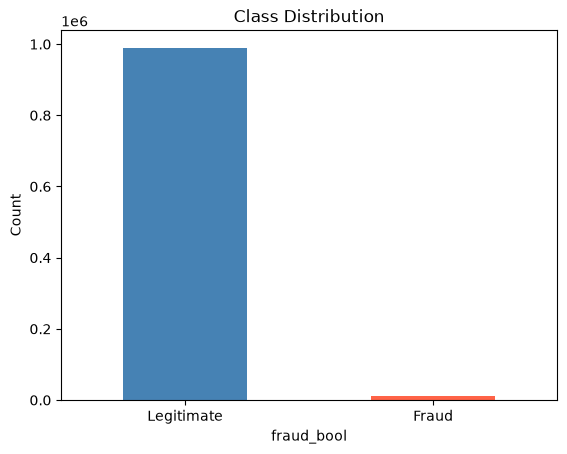

In [45]:
counts = df['fraud_bool'].value_counts()
print(counts)
print("\nFraud percentage:", round(df['fraud_bool'].mean() * 100, 2), "%")

# Plot
df['fraud_bool'].value_counts().sort_index().plot(kind='bar', color=['steelblue', 'tomato'])
plt.xticks([0, 1], ['Legitimate', 'Fraud'], rotation=0)
plt.title('Class Distribution')
plt.ylabel('Count')
plt.show()

In [46]:
df.describe()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_6h,...,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,session_length_in_minutes,keep_alive_session,device_distinct_emails_8w,month
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,...,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,0.011029,0.562696,0.493694,16.718568,86.587867,33.689080,1.025705e+00,8.661498,1572.692049,5665.296387,...,0.417077,0.889676,10.839303,0.222988,515.851013,0.025242,7.544940,0.576947,1.018312,3.288674
std,0.104438,0.290343,0.289125,44.046230,88.406599,12.025799,5.381835e+00,20.236155,1005.374565,3009.380615,...,0.493076,0.313293,12.116875,0.416251,487.559906,0.156859,8.033107,0.494044,0.180761,2.209994
min,0.000000,0.100000,0.000001,-1.000000,-1.000000,10.000000,4.036860e-09,-15.530555,1.000000,-170.603073,...,0.000000,0.000000,-1.000000,0.000000,190.000000,0.000000,-1.000000,0.000000,-1.000000,0.000000
25%,0.000000,0.300000,0.225216,-1.000000,19.000000,20.000000,7.193246e-03,-1.181488,894.000000,3436.365906,...,0.000000,1.000000,-1.000000,0.000000,200.000000,0.000000,3.103053,0.000000,1.000000,1.000000
50%,0.000000,0.600000,0.492153,-1.000000,52.000000,30.000000,1.517574e-02,-0.830507,1263.000000,5319.769531,...,0.000000,1.000000,5.000000,0.000000,200.000000,0.000000,5.114321,1.000000,1.000000,3.000000
75%,0.000000,0.800000,0.755567,12.000000,130.000000,40.000000,2.633069e-02,4.984176,1944.000000,7680.717773,...,1.000000,1.000000,25.000000,0.000000,500.000000,0.000000,8.866131,1.000000,1.000000,5.000000
max,1.000000,0.900000,0.999999,383.000000,428.000000,90.000000,7.845690e+01,112.956924,6700.000000,16715.564453,...,1.000000,1.000000,32.000000,1.000000,2100.000000,1.000000,85.899139,1.000000,2.000000,7.000000


In [47]:
# Separate numerical and categorical columns
# (text columns are stored as 'category' by reduce_memory; this line works in pandas 2 and 3)
categorical_cols = df.select_dtypes(include=['category', 'object', 'string']).columns.tolist()
numerical_cols = df.select_dtypes(include='number').columns.tolist()
numerical_cols.remove('fraud_bool')  # remove target variable

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

Categorical columns: ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']

Numerical columns: ['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'credit_risk_score', 'email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'session_length_in_minutes', 'keep_alive_session', 'device_distinct_emails_8w', 'month']


In [48]:
for col in categorical_cols:
    print(f"{col}: {list(df[col].unique())}")

payment_type: ['AA', 'AD', 'AB', 'AC', 'AE']
employment_status: ['CB', 'CA', 'CC', 'CF', 'CD', 'CE', 'CG']
housing_status: ['BC', 'BE', 'BD', 'BA', 'BB', 'BF', 'BG']
source: ['INTERNET', 'TELEAPP']
device_os: ['linux', 'other', 'windows', 'x11', 'macintosh']


## Age and categorical features vs fraud

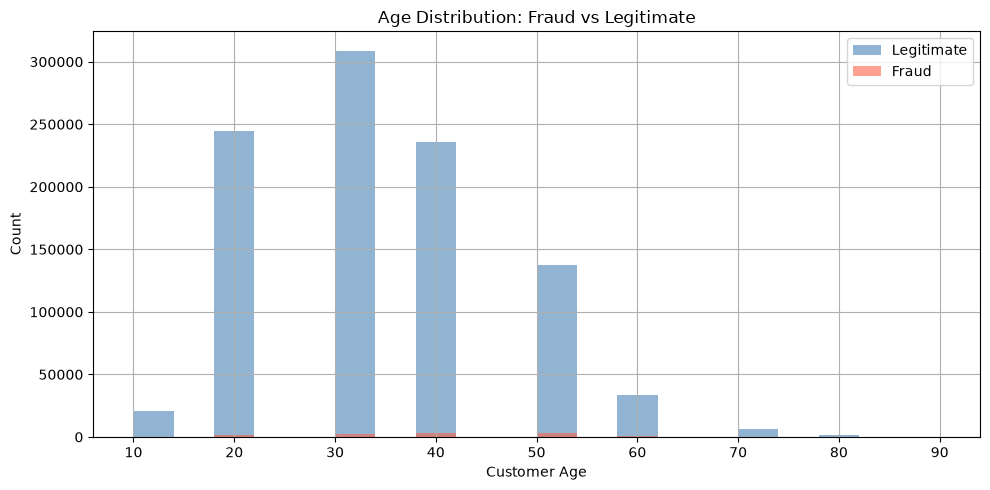

In [49]:
plt.figure(figsize=(10, 5))
df[df['fraud_bool'] == 0]['customer_age'].hist(alpha=0.6, bins=20, label='Legitimate', color='steelblue')
df[df['fraud_bool'] == 1]['customer_age'].hist(alpha=0.6, bins=20, label='Fraud', color='tomato')
plt.xlabel('Customer Age')
plt.ylabel('Count')
plt.title('Age Distribution: Fraud vs Legitimate')
plt.legend()
plt.tight_layout()
plt.show()

Fraud rate by age group (%):
age_group
<20      0.35
20-29    0.49
30-39    0.83
40-49    1.20
50-59    2.00
60+      3.47
Name: fraud_bool, dtype: float64


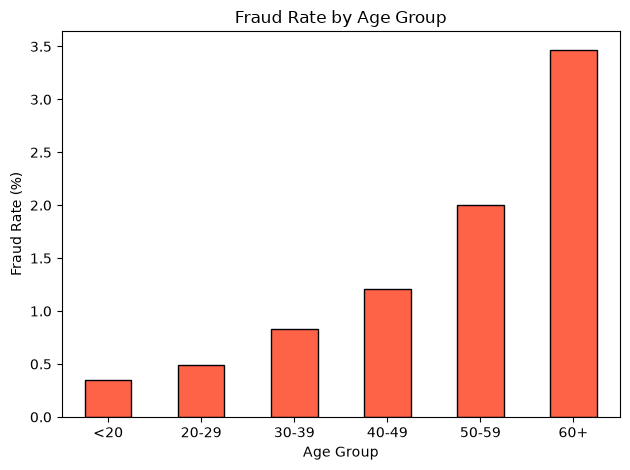

In [50]:
# Create age groups
df['age_group'] = pd.cut(df['customer_age'],
                          bins=[0, 20, 30, 40, 50, 60, 100],
                          labels=['<20', '20-29', '30-39', '40-49', '50-59', '60+'],
                          right=False)

# Fraud rate per age group
fraud_by_age = df.groupby('age_group', observed=True)['fraud_bool'].mean() * 100

print("Fraud rate by age group (%):")
print(fraud_by_age.round(2))

# Plot
fraud_by_age.plot(kind='bar', color='tomato', edgecolor='black')
plt.title('Fraud Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [51]:
for col in ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']:
    fraud_rate = df.groupby(col, observed=True)['fraud_bool'].mean() * 100
    print(f"\nFraud rate by {col} (%):")
    print(fraud_rate.round(2).sort_values(ascending=False))


Fraud rate by payment_type (%):
payment_type
AC    1.67
AB    1.13
AD    1.08
AA    0.53
AE    0.35
Name: fraud_bool, dtype: float64

Fraud rate by employment_status (%):
employment_status
CC    2.47
CG    1.55
CA    1.22
CB    0.69
CD    0.38
CE    0.23
CF    0.19
Name: fraud_bool, dtype: float64

Fraud rate by housing_status (%):
housing_status
BA    3.75
BD    0.86
BC    0.61
BB    0.60
BF    0.42
BG    0.40
BE    0.34
Name: fraud_bool, dtype: float64

Fraud rate by source (%):
source
TELEAPP     1.59
INTERNET    1.10
Name: fraud_bool, dtype: float64

Fraud rate by device_os (%):
device_os
windows      2.47
macintosh    1.40
x11          1.12
other        0.58
linux        0.52
Name: fraud_bool, dtype: float64


## Preparing data for modelling
**No LabelEncoder.** Categorical columns stay as the `category` type, so their real names (e.g. employment status) remain readable for SHAP plots and the fairness audit:
- Logistic regression uses one-hot encoding inside its pipeline (LabelEncoder would impose a false ordering on the categories).
- LightGBM can use `category` columns directly in the next notebook.

**Protected attributes** (`customer_age`, `income`, `employment_status`) are currently kept as model features. Whether to keep them in or use them only for the audit is a methodological decision to justify in the dissertation.

In [52]:
df = df.drop(columns=['age_group'])  # only needed for EDA

PROTECTED_ATTRIBUTES = ['customer_age', 'income', 'employment_status']
TARGET = 'fraud_bool'

## Train/test split
The BAF paper uses a **temporal split**: months 0–5 for training and months 6–7 for testing. This mimics deployment (train on the past, predict the future) and makes results comparable with the BAF benchmark. `month` is then removed from the features, because the model shouldn't learn from the calendar month itself.

Set `SPLIT_METHOD = 'random'` to use a stratified random 90/10 split instead (this choice would need justifying).

In [53]:
from sklearn.model_selection import train_test_split

SPLIT_METHOD = 'temporal'   # 'temporal' (BAF paper) or 'random'

if SPLIT_METHOD == 'temporal':
    train_mask = df['month'] <= 5
    train_df, test_df = df[train_mask], df[~train_mask]
else:
    train_df, test_df = train_test_split(
        df, test_size=0.1, random_state=RANDOM_STATE, stratify=df[TARGET]
    )

FEATURES = [c for c in df.columns if c not in [TARGET, 'month']]
CAT_FEATURES = [c for c in categorical_cols if c in FEATURES]
NUM_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

del train_df, test_df
gc.collect()

print(f"Split method: {SPLIT_METHOD}")
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print(f"\nFraud rate in training set: {y_train.mean() * 100:.2f}%  ({y_train.sum()} cases)")
print(f"Fraud rate in test set:     {y_test.mean() * 100:.2f}%  ({y_test.sum()} cases)")

Split method: temporal
Training set size: (794989, 29)
Test set size: (205011, 29)

Fraud rate in training set: 1.03%  (8151 cases)
Fraud rate in test set:     1.40%  (2878 cases)


## Evaluation function
Fraud is ~1% of cases, so accuracy and AUC-ROC look optimistic. As set out in the proposal, models are compared on **AUC-PR, precision, recall and F1**. **Recall at 5% false-positive rate** is also reported because it is the headline metric in the BAF paper.

In [54]:
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, roc_curve, confusion_matrix,
)

def recall_at_fpr(y_true, y_prob, target_fpr=0.05):
    """Highest recall achievable while keeping the false-positive rate at or below target_fpr."""
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return float(tpr[fpr <= target_fpr].max())

def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    print(f"--- {name} (threshold = {threshold}) ---")
    print(classification_report(y_true, y_pred, target_names=['Legitimate', 'Fraud'], digits=3))
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_true, y_pred))
    results = {
        'model': name,
        'AUC-ROC': roc_auc_score(y_true, y_prob),
        'AUC-PR': average_precision_score(y_true, y_prob),
        'Recall@5%FPR': recall_at_fpr(y_true, y_prob, 0.05),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
    }
    print({k: round(v, 4) for k, v in results.items() if k != 'model'})
    return results

all_results = []

## Baseline: logistic regression

In [55]:
import time
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocess = ColumnTransformer([
    ('num', StandardScaler(), NUM_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
])

lr_model = Pipeline([
    ('preprocess', preprocess),
    ('classifier', LogisticRegression(
        class_weight='balanced',   # handles the ~1% class imbalance
        max_iter=2000,
        random_state=RANDOM_STATE,
    )),
])

print("Training Logistic Regression (scaled numeric + one-hot categorical)...")
start = time.time()
lr_model.fit(X_train, y_train)
print(f"Training complete in {round(time.time() - start, 1)} seconds\n")

lr_prob = lr_model.predict_proba(X_test)[:, 1]
all_results.append(evaluate('Logistic Regression', y_test, lr_prob))

Training Logistic Regression (scaled numeric + one-hot categorical)...
Training complete in 3.4 seconds

--- Logistic Regression (threshold = 0.5) ---
              precision    recall  f1-score   support

  Legitimate      0.996     0.834     0.908    202133
       Fraud      0.061     0.759     0.113      2878

    accuracy                          0.833    205011
   macro avg      0.528     0.796     0.510    205011
weighted avg      0.983     0.833     0.897    205011

Confusion matrix [[TN, FP], [FN, TP]]:
[[168535  33598]
 [   693   2185]]
{'AUC-ROC': 0.8779, 'AUC-PR': 0.1582, 'Recall@5%FPR': 0.4969, 'Precision': 0.0611, 'Recall': 0.7592, 'F1': 0.113}


## Save outputs for the next notebooks

In [56]:
import joblib

# Processed train/test sets (category types are preserved in Parquet)
X_train.to_parquet(OUTPUT_DIR / 'processed' / 'X_train.parquet')
X_test.to_parquet(OUTPUT_DIR / 'processed' / 'X_test.parquet')
y_train.to_frame().to_parquet(OUTPUT_DIR / 'processed' / 'y_train.parquet')
y_test.to_frame().to_parquet(OUTPUT_DIR / 'processed' / 'y_test.parquet')

# Trained model and feature lists
joblib.dump(lr_model, OUTPUT_DIR / 'models' / 'logistic_regression.joblib')
joblib.dump(
    {'FEATURES': FEATURES, 'CAT_FEATURES': CAT_FEATURES, 'NUM_FEATURES': NUM_FEATURES,
     'PROTECTED_ATTRIBUTES': PROTECTED_ATTRIBUTES, 'SPLIT_METHOD': SPLIT_METHOD},
    OUTPUT_DIR / 'models' / 'feature_config.joblib',
)

# Results table
results_df = pd.DataFrame(all_results).round(4)
results_df.to_csv(OUTPUT_DIR / 'results' / 'baseline_results.csv', index=False)
print(f"Saved outputs to {OUTPUT_DIR}")
results_df

Saved outputs to /Users/lucy/Desktop/PROJ519 MSc Dissertation and Research Skills/analysis/outputs


,model,AUC-ROC,AUC-PR,Recall@5%FPR,Precision,Recall,F1
0,Logistic Regression,0.8779,0.1582,0.4969,0.0611,0.7592,0.113
